# Phase 0–1: Data preparation, quality control and exploratory analysis

**Project:** surrogate estimation of BOD and COD from routinely measured EC, pH and DO in five rivers around Dhaka, Bangladesh (DoE monitoring data, 2017–2022).
**Purpose:** build the analysis datasets, document every data-quality decision, freeze the outer validation folds, and describe the data before any modelling.

### Phase 0
- **0.1** Integrity and provenance checks
- **0.2** Build the analysis datasets
- **0.3** Freeze the outer validation folds

### Phase 1
- **1.1** Univariate distributions
- **1.2** Bivariate relationships and collinearity
- **1.3** Spatial heterogeneity — ICC and nested sum-of-squares shares
- **1.4** Temporal structure — structural-break screening
- **1.5** Effective sample size
- **1.6** Temporal variance decomposition — month and season

> **Analysis rule:** this notebook is descriptive/QC only. No model-selection decision is made from the test folds. Any transformation used later is defined in `src.preprocessing`, and fold-safe preprocessing remains inside the modelling pipeline.

## Data-handling assumptions

Every choice below is made once, here, and applies to all later notebooks. Each is tested in a sensitivity analysis: the ones in this repository are linked; the others belong to the full study, which will be released with the publication.

| Issue | Choice in the primary analysis | Where it is tested |
|---|---|---|
| **DO reported as 0.0 mg/L** | Kept as reported. DoE does not disclose its reporting limit, so a zero is read as a left-censored value below an unknown limit. `log1p` keeps it finite. | Sensitivity analysis (full study) |
| **Potential cross-river duplicates** — rows whose measurements are identical to a row recorded under another river (listed in 0.1g) | Retained: DoE could not confirm that they are errors | Phase 3, 3.6b: refit without them |
| **Implausible BOD/COD ratio** (outside `BOD_COD_RATIO_RANGE`) — listed in 0.1h | Retained and listed in `phase0_ratio_flags.csv` | Sensitivity analysis (full study) |
| **Missing values** | Complete cases per dataset (DS-3F, DS-4F, DS-4F-ALK, DS-5F); no imputation | 0.2b shows where rows are lost |
| **Target transform** | `log1p` for BOD and COD; the inverse is `expm1` | Fixed a priori |
| **Predictor transforms** | `log` for EC and TDS (strictly positive), `log1p` for DO (has zeros), pH untransformed | Phase 2, 2.3: raw representation as a robustness check |
| **Exceedance of a limit** | value **>** limit (ECR 2023 limits are upper limits) | Sensitivity analysis (full study) |
| **Reporting resolution** | Values used as reported | Sensitivity analysis (full study) |
| **Sampling dates** | Not available; each observation belongs to a monthly sampling campaign (year-month) | Dependence within campaigns is quantified in 1.5 |
| **Measurement method** | All parameters, DO, pH and EC included, are laboratory determinations by DoE | — |

In [1]:
# Setup. `pip install -e .` from the repository root makes `src` importable (README);
# without it, the repository root (the parent of notebooks/) is added to the path.
try:
    import src  # noqa: F401
except ModuleNotFoundError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(Path.cwd().resolve().parent))

import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import *
from src.data_loading import (
    load_locked_dataset,
    build_datasets,
    run_integrity_checks,
    print_checks,
    check_status,
    observation_key,
    find_cross_river_duplicates,
    exclude_flagged_cross_river_duplicates,
)
from src.folds import (
    build_loso_river,
    build_loso_station,
    build_fc,
    build_stratified_kfold,
    build_random_splits,
    save_all_folds,
    save_fold_keys,
)
from src.preprocessing import target_forward, target_inverse, inspect_pca_block
from src.stats import (
    true_icc, nested_variance_decomposition, partial_corr, chow_test,
    clustered_break_test, vif,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Data directory   :", rel(DATA_DIR))
print("Results directory:", rel(RESULTS_DIR))
print("Figures directory:", rel(FIGURES_DIR))
print("Random seed      :", SEED)

Data directory   : data
Results directory: results
Figures directory: figures
Random seed      : 42


## 0.1 Integrity checks

The raw CSV is checked before any analysis dataset is built.

The important distinction is between:

1. **confirmed structural problems** — e.g. duplicate station/year/month records;
2. **plausibility flags** — e.g. unusual BOD/COD ratios;
3. **unresolved provenance issues** — potential cross-river duplicate observations.

The latter are **not silently deleted** because the source agency could not confirm that they are erroneous. They remain in the primary datasets and are retained for sensitivity analysis.

In [2]:
# Load the raw CSV using the project's configured path and column names.
raw_path = RAW_CSV
if not raw_path.exists():
    raise FileNotFoundError(
        f"Raw CSV not found at {rel(raw_path)}. "
        "See data/README.md for the expected file and columns."
    )

try:
    raw = pd.read_csv(raw_path, encoding="utf-8")
except UnicodeDecodeError:
    raw = pd.read_csv(raw_path, encoding="latin-1")

raw = raw.rename(columns=COLUMN_RENAME)

print(f"Raw dataset: {raw.shape[0]:,} rows × {raw.shape[1]:,} columns")
display(raw.head())
display(raw.dtypes.to_frame("dtype"))

Raw dataset: 1,184 rows × 25 columns


,ID,Source,River,Place,Lat,Long,Lat_decimal,Long_decimal,Year,Month,Month_num,Season,pH,DO,BOD,COD,log_BOD,log_COD,BOD_COD_ratio,TDS,Turbidity,Chloride,SS,Alkalinity,EC
0,1,DoE,Buriganga,Mirpur Bridge,"23°47'8.13""N","90°20'10.21""E",23.7856,90.3362,2017,January,1,Dry,7.7400,0.2000,11.2000,46.0000,2.5014,3.8501,0.2435,360.0000,38.0000,45.0000,38.0000,224.0000,745.0000
1,2,DoE,Buriganga,Mirpur Bridge,"23°47'8.13""N","90°20'10.21""E",23.7856,90.3362,2017,February,2,Dry,7.1400,0.2000,18.6000,72.0000,2.9755,4.2905,0.2583,484.0000,75.0000,49.0000,118.0000,280.0000,904.0000
2,3,DoE,Buriganga,Mirpur Bridge,"23°47'8.13""N","90°20'10.21""E",23.7856,90.3362,2017,March,3,Dry,7.3100,0.1000,28.2000,88.0000,3.3742,4.4886,0.3205,538.0000,75.0000,65.0000,118.0000,280.0000,"1,054.0000"
3,4,DoE,Buriganga,Mirpur Bridge,"23°47'8.13""N","90°20'10.21""E",23.7856,90.3362,2017,April,4,Dry,6.7200,2.4000,7.5000,26.0000,2.1401,3.2958,0.2885,372.0000,29.7000,30.0000,49.0000,180.0000,744.0000
4,5,DoE,Buriganga,Mirpur Bridge,"23°47'8.13""N","90°20'10.21""E",23.7856,90.3362,2017,May,5,Wet,7.5500,0.5000,8.8000,36.0000,2.2824,3.6109,0.2444,272.0000,13.9000,23.0000,31.0000,130.0000,544.0000


,dtype
ID,int64
Source,str
River,str
Place,str
Lat,str
Long,str
Lat_decimal,float64
Long_decimal,float64
Year,int64
Month,str


In [3]:
# Exp 0.1a — station inventory

required = ["River", "Place", "Year", "Month_num"]

missing = [c for c in required if c not in raw.columns]
if missing:
    raise KeyError(f"Missing required station/time columns: {missing}")

stations = (
    raw.groupby(["River", "Place"], dropna=False)
       .agg(
           n=("ID", "count"),
           lat=("Lat_decimal", "first"),
           lon=("Long_decimal", "first"),
           year_min=("Year", "min"),
           year_max=("Year", "max"),
       )
       .reset_index()
)

print(f"Unique (River, Place) combinations: {len(stations)}")

assert len(stations) == EXPECTED_STATIONS, (
    f"Expected {EXPECTED_STATIONS} stations, got {len(stations)}"
)

# Build station inventory.
station_inventory = (
    stations.assign(
        years=lambda x: (
            x["year_min"].astype(str) + "–" + x["year_max"].astype(str)
        )
    )
    .drop(columns=["year_min", "year_max"])
)

# Apply the locked deterministic river order.
station_inventory["River"] = pd.Categorical(
    station_inventory["River"],
    categories=RIVER_ORDER,
    ordered=True,
)

# Sort by river order, then station/place name.
station_inventory = (
    station_inventory
    .sort_values(
        ["River", "Place"],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

display(station_inventory)

# Save deterministic station inventory.
station_inventory.to_csv(
    RESULTS_DIR / "phase0_station_inventory.csv",
    index=False,
)

Unique (River, Place) combinations: 30


,River,Place,n,lat,lon,years
0,Buriganga,BD CHN Frp. Brid,68,23.6872,90.4268,2017–2022
1,Buriganga,Bosila Bridge,21,23.7431,90.3452,2021–2022
2,Buriganga,Chadnighat,68,23.7107,90.3910,2017–2022
3,Buriganga,Dholaikhal,46,23.7086,90.4019,2017–2020
4,Buriganga,Fatullah,21,23.6480,90.4669,2021–2022
5,Buriganga,Hazaribagh,68,23.7217,90.3596,2017–2022
6,Buriganga,Kamarangirchar,68,23.7080,90.3685,2017–2022
7,Buriganga,Mirpur Bridge,70,23.7856,90.3362,2017–2022
8,Buriganga,Pagla,40,23.6623,90.4536,2017–2020
9,Buriganga,Sadarghat,46,23.7039,90.4091,2017–2020


In [4]:
# Exp 0.1b — duplicate check at the intended observational unit
dup_counts = (
    raw.groupby(["River", "Place", "Year", "Month_num"], dropna=False)
       .size()
       .rename("n")
)
duplicates = dup_counts[dup_counts > 1].reset_index()

print(f"Confirmed duplicate station/year/month combinations: {len(duplicates)}")
if len(duplicates):
    display(duplicates)
    raise AssertionError(
        "Confirmed duplicate observational units exist. Resolve them before "
        "building the locked datasets."
    )
else:
    print("✓ No confirmed same-station/year/month duplicates.")

Confirmed duplicate station/year/month combinations: 0
✓ No confirmed same-station/year/month duplicates.


In [5]:
# Exp 0.1c–f — physical plausibility and provenance flags
print("PHYSICAL PLAUSIBILITY CHECKS")
print("=" * 70)

checks = {}

for col in ["BOD", "COD"]:
    vals = raw[col].dropna()
    n_le0 = int((vals <= 0).sum())
    checks[col] = {"min": vals.min(), "max": vals.max(), "n_nonpositive": n_le0}
    print(f"{col:>5}: min={vals.min():.3f}, max={vals.max():.3f}, n≤0={n_le0}")

ph = raw["pH"].dropna()
n_ph = int(((ph < PH_RANGE[0]) | (ph > PH_RANGE[1])).sum())
checks["pH"] = {"min": ph.min(), "max": ph.max(), "n_outside": n_ph}
print(f"pH   : range={ph.min():.3f}–{ph.max():.3f}, outside {PH_RANGE}: {n_ph}")

do = raw["DO"].dropna()
n_do = int((do < 0).sum())
checks["DO"] = {"min": do.min(), "max": do.max(), "n_negative": n_do}
print(f"DO   : min={do.min():.3f}, max={do.max():.3f}, n<0={n_do}")

ratio = (raw["BOD"] / raw["COD"]).replace([np.inf, -np.inf], np.nan).dropna()
n_ratio = int(((ratio < BOD_COD_RATIO_RANGE[0]) | (ratio > BOD_COD_RATIO_RANGE[1])).sum())
checks["BOD_COD_ratio"] = {
    "min": ratio.min(), "max": ratio.max(), "mean": ratio.mean(),
    "n_outside": n_ratio,
}
print(
    f"BOD/COD: range={ratio.min():.3f}–{ratio.max():.3f}, "
    f"mean={ratio.mean():.3f}, outside {BOD_COD_RATIO_RANGE}: {n_ratio}"
)

# Missingness in the raw file.
missingness = (
    raw.isna().sum()
       .rename("n_missing")
       .to_frame()
       .assign(pct_missing=lambda x: 100 * x["n_missing"] / len(raw))
       .sort_values("pct_missing", ascending=False)
)
display(missingness)

missingness.to_csv(RESULTS_DIR / "phase0_raw_missingness.csv")

PHYSICAL PLAUSIBILITY CHECKS
  BOD: min=0.200, max=88.500, n≤0=0
  COD: min=1.740, max=356.000, n≤0=0
pH   : range=6.300–8.810, outside (5.5, 9.5): 0
DO   : min=0.000, max=8.300, n<0=0
BOD/COD: range=0.008–1.000, mean=0.296, outside (0.05, 0.8): 25


,n_missing,pct_missing
Turbidity,423,35.7264
TDS,89,7.5169
SS,73,6.1655
Chloride,42,3.5473
BOD_COD_ratio,35,2.9561
pH,32,2.7027
log_BOD,30,2.5338
BOD,30,2.5338
Alkalinity,19,1.6047
EC,18,1.5203


In [6]:
# Exp 0.1g — coordinate verification
coord_cols = ["Lat_decimal", "Long_decimal"]
coords = raw.groupby(["River", "Place"])[coord_cols].first().reset_index()

outside = coords[
    (coords["Lat_decimal"] < 23.5) | (coords["Lat_decimal"] > 24.2) |
    (coords["Long_decimal"] < 90.1) | (coords["Long_decimal"] > 90.8)
]

if len(outside):
    print("⚠ Stations outside the broad Dhaka-area bounds:")
    display(outside)
else:
    print("✓ All station coordinates fall within the broad Dhaka-area bounds.")
    print(
        f"Latitude range: {coords['Lat_decimal'].min():.4f}–{coords['Lat_decimal'].max():.4f}; "
        f"longitude range: {coords['Long_decimal'].min():.4f}–{coords['Long_decimal'].max():.4f}"
    )

# Cross-river duplicate provenance check.
# These are flagged, not removed.
# Add the observation key in the same way as the locked loader.
tmp = raw.copy()
tmp["Observation_Key"] = (
    tmp["River"].astype(str).str.strip() + "||" +
    tmp["Place"].astype(str).str.strip() + "||" +
    tmp["Year"].astype(str) + "||" +
    tmp["Month_num"].astype(str)
)
cross_dupes = find_cross_river_duplicates(tmp)

print(f"\nPotential cross-river duplicate observations: {cross_dupes['Observation_Key'].nunique()}")
if not cross_dupes.empty:
    display(cross_dupes.head(30))
    cross_dupes.to_csv(RESULTS_DIR / "phase0_cross_river_duplicate_flags.csv", index=False)
else:
    print("✓ No cross-river duplicate pattern detected.")

✓ All station coordinates fall within the broad Dhaka-area bounds.
Latitude range: 23.6282–23.9898; longitude range: 90.3288–90.6358

Potential cross-river duplicate observations: 8


,Observation_Key,Year,Month_num,pH,DO,BOD,COD,TDS,EC,River,Place
0,Tongi Khal||Near Jaber & Jubair||2019||12,2019,12,7.0300,0.0000,12.6000,73.0000,361.0000,634.0000,Tongi Khal,Near Jaber & Jubair
1,Turag||New Gabtoli Bridge||2019||12,2019,12,7.0300,0.0000,12.6000,73.0000,361.0000,634.0000,Turag,New Gabtoli Bridge
2,Tongi Khal||Hossain Dyeing||2019||12,2019,12,7.3400,0.0000,12.4000,66.0000,264.0000,469.0000,Tongi Khal,Hossain Dyeing
3,Turag||Mirpur Diabari BIWTA LS||2019||12,2019,12,7.3400,0.0000,12.4000,66.0000,264.0000,469.0000,Turag,Mirpur Diabari BIWTA LS
4,Balu River||Balu Bridge||2019||12,2019,12,7.6900,0.0000,8.6000,39.0000,350.0000,617.0000,Balu River,Balu Bridge
5,Turag||Tongi Istima||2019||12,2019,12,7.6900,0.0000,8.6000,39.0000,350.0000,617.0000,Turag,Tongi Istima
6,Balu River||Demra University||2019||12,2019,12,7.7300,0.0000,12.2000,56.0000,387.0000,679.0000,Balu River,Demra University
7,Turag||Ashulia BIWTA LS||2019||12,2019,12,7.7300,0.0000,12.2000,56.0000,387.0000,679.0000,Turag,Ashulia BIWTA LS


In [7]:
# Exp 0.1h — official integrity checks with PASS / FLAG / FAIL status
raw_locked_like = tmp.sort_values(
    ["River", "Place", "Year", "Month_num", "ID"], kind="mergesort"
).reset_index(drop=True)

integrity = run_integrity_checks(raw_locked_like)
print_checks(integrity)          # ✓ PASS   ⚠ FLAG (retained, listed)   ✗ FAIL
pd.DataFrame(integrity).T.to_csv(RESULTS_DIR / "phase0_integrity_checks_src_raw.csv")

integrity_table = pd.DataFrame([
    {"check": k, "status": check_status(v),
     "detail": ", ".join(f"{kk}={vv}" for kk, vv in v.items() if kk not in ("ok", "flagged"))}
    for k, v in integrity.items()
])
display(integrity_table)
integrity_table.to_csv(RESULTS_DIR / "phase0_integrity_checks.csv", index=False)

# Rows outside the plausible BOD/COD range, for the record (retained).
ratio_all = raw["BOD"] / raw["COD"]
lo, hi = BOD_COD_RATIO_RANGE
ratio_flag_mask = ratio_all.notna() & ((ratio_all < lo) | (ratio_all > hi))
n_ratio_flag = int(ratio_flag_mask.sum())
n_bod_eq_cod = int(np.isclose(ratio_all, 1.0).sum())
ratio_flags = (
    raw.loc[ratio_flag_mask, ["ID", "River", "Place", "Year", "Month_num", "BOD", "COD"]]
    .assign(BOD_COD_ratio=ratio_all[ratio_flag_mask])
    .sort_values("BOD_COD_ratio")
)
print(f"{n_ratio_flag} rows outside {BOD_COD_RATIO_RANGE}; {n_bod_eq_cod} with BOD = COD.")
display(ratio_flags)
ratio_flags.to_csv(RESULTS_DIR / "phase0_ratio_flags.csv", index=False)

failed = integrity_table.loc[integrity_table["status"].eq("FAIL"), "check"].tolist()
if failed:
    raise AssertionError(f"Integrity checks failed: {failed}. Resolve before building datasets.")

  ✓ 0.1a_stations: {'value': 30, 'expected': 30, 'ok': True}
  ✓ 0.1b_duplicates: {'value': 0, 'expected': 0, 'ok': np.True_}
  ✓ 0.1c_positive: {'BOD_min': np.float64(0.2), 'COD_min': np.float64(1.74), 'ok': np.True_}
  ⚠ 0.1c_cross_river_duplicates: {'n_flagged': 8, 'ok': True, 'flagged': True}
  ⚠ 0.1d_ratio: {'n_outside': 25, 'pct': '2.1%', 'mean': '0.30', 'n_bod_equals_cod': 4, 'ok': True, 'flagged': True}
  ✓ 0.1d_bod_le_cod: {'n_bod_gt_cod': 0, 'ok': True}
  ✓ 0.1e_pH: {'n_outside': 0, 'range': '6.3–8.8', 'ok': True}
  ✓ 0.1f_DO: {'n_negative': 0, 'min': np.float64(0.0), 'ok': True}
  ✓ 0.1g_log_transform: {'transform': 'log1p', 'ok': True}


,check,status,detail
0,0.1a_stations,PASS,"value=30, expected=30"
1,0.1b_duplicates,PASS,"value=0, expected=0"
2,0.1c_positive,PASS,"BOD_min=0.2, COD_min=1.74"
3,0.1c_cross_river_duplicates,FLAG,n_flagged=8
4,0.1d_ratio,FLAG,"n_outside=25, pct=2.1%, mean=0.30, n_bod_equal..."
5,0.1d_bod_le_cod,PASS,n_bod_gt_cod=0
6,0.1e_pH,PASS,"n_outside=0, range=6.3–8.8"
7,0.1f_DO,PASS,"n_negative=0, min=0.0"
8,0.1g_log_transform,PASS,transform=log1p


25 rows outside (0.05, 0.8); 4 with BOD = COD.


,ID,River,Place,Year,Month_num,BOD,COD,BOD_COD_ratio
439,440,Shitalakhya,Ghorashal,2019,10,0.4000,49.0000,0.0082
715,716,Buriganga,Bosila Bridge,2021,7,1.0000,66.0000,0.0152
34,35,Buriganga,Kamarangirchar,2017,11,0.2000,10.0000,0.0200
798,799,Shitalakhya,Ghorashal,2021,10,1.0000,39.0000,0.0256
733,734,Buriganga,Kamarangirchar,2021,7,2.0000,73.0000,0.0274
724,725,Buriganga,Hazaribagh,2021,7,1.0000,36.0000,0.0278
8,9,Buriganga,Mirpur Bridge,2017,9,0.8000,22.0000,0.0364
734,735,Buriganga,Kamarangirchar,2021,8,5.0000,122.0000,0.0410
786,787,Shitalakhya,Murapara,2021,7,1.0000,24.0000,0.0417
1159,1201,Tongi Khal,Near Jaber & Jubair,2017,9,1.2000,28.0000,0.0429


## 0.2 Build and lock DS-3F / DS-4F / DS-4F-ALK / DS-5F

The dataset construction is delegated to `src.data_loading.build_datasets()` so that the notebook and the modeling code share exactly the same data contract.

The locked expected sizes are:

| Dataset | Features | Expected rows |
|---|---|---:|
| DS-3F | EC, pH, DO | 1,131 |
| DS-4F | EC, pH, DO, TDS | 1,083 |
| DS-4F-ALK | EC, pH, DO, Alkalinity | 1,129 |
| DS-5F | EC, pH, DO, TDS, Turbidity | 710 |

The source-level cross-river duplicate flags are retained rather than deleted.

In [8]:
# Build the locked datasets once.
datasets_built = build_datasets(RAW_CSV)

dataset_summary = []
for name, d in datasets_built.items():
    dataset_summary.append({
        "dataset": name,
        "n_rows": len(d),
        "n_rivers": d["River"].nunique(),
        "n_stations": d.groupby(["River", "Place"]).ngroups,
        "years": f"{int(d['Year'].min())}–{int(d['Year'].max())}",
        "cross_river_flagged": int(d["Potential_CrossRiver_Duplicate"].fillna(False).sum())
            if "Potential_CrossRiver_Duplicate" in d else 0,
    })

dataset_summary = pd.DataFrame(dataset_summary)
display(dataset_summary)
dataset_summary.to_csv(RESULTS_DIR / "phase0_dataset_summary.csv", index=False)

Raw: 1184 rows, 25 cols
Target transform contract OK: log1p
  DS-3F: 1131 rows → DS_3F.csv
  DS-4F: 1083 rows → DS_4F.csv
  DS-4F-ALK: 1129 rows → DS_4F_ALK.csv
  DS-5F: 710 rows → DS_5F.csv


,dataset,n_rows,n_rivers,n_stations,years,cross_river_flagged
0,DS-3F,1131,5,30,2017–2022,8
1,DS-4F,1083,5,30,2017–2022,8
2,DS-4F-ALK,1129,5,30,2017–2022,8
3,DS-5F,710,4,17,2017–2022,4


In [9]:
# Reload through the locked loader — this is the object used downstream.
locked = {}
for name in ["DS-3F", "DS-4F", "DS-4F-ALK", "DS-5F"]:
    locked[name] = load_locked_dataset(name)

for name, d in locked.items():
    print(
        f"{name:10s}: n={len(d):4d}, rivers={d['River'].nunique()}, "
        f"stations={d.groupby(['River','Place']).ngroups}"
    )

# Target-transform contract check.
for name, d in locked.items():
    max_dev_bod = np.max(np.abs(d["log_BOD"] - target_forward(d["BOD"].to_numpy())))
    max_dev_cod = np.max(np.abs(d["log_COD"] - target_forward(d["COD"].to_numpy())))
    print(f"{name}: max |stored log_BOD - log1p(BOD)| = {max_dev_bod:.3e}; "
          f"max |stored log_COD - log1p(COD)| = {max_dev_cod:.3e}")

print(f"TARGET_TRANSFORM = {TARGET_TRANSFORM!r}")

DS-3F     : n=1131, rivers=5, stations=30
DS-4F     : n=1083, rivers=5, stations=30
DS-4F-ALK : n=1129, rivers=5, stations=30
DS-5F     : n= 710, rivers=4, stations=17
DS-3F: max |stored log_BOD - log1p(BOD)| = 0.000e+00; max |stored log_COD - log1p(COD)| = 0.000e+00
DS-4F: max |stored log_BOD - log1p(BOD)| = 0.000e+00; max |stored log_COD - log1p(COD)| = 0.000e+00
DS-4F-ALK: max |stored log_BOD - log1p(BOD)| = 0.000e+00; max |stored log_COD - log1p(COD)| = 0.000e+00
DS-5F: max |stored log_BOD - log1p(BOD)| = 0.000e+00; max |stored log_COD - log1p(COD)| = 0.000e+00
TARGET_TRANSFORM = 'log1p'


### 0.2b Where complete-case filtering removes rows

Complete-case filtering is not uniform across stations or years. The first table shows, per station, how many raw rows survive into each locked dataset. The second lists the rows present in DS-3F but absent from DS-4F — rows lost *only* because TDS is missing. If those rows cluster in one river-year, any analysis run on DS-4F loses that river-year even when TDS is not a predictor.

In [10]:
# Exp 0.2b — complete-case losses by station, and the DS-3F -> DS-4F (TDS) gap

loss = raw.groupby(["River", "Place"]).size().rename("raw").to_frame()
for name, d in locked.items():
    loss[name] = d.groupby(["River", "Place"]).size()
loss = loss.fillna(0).astype(int)
loss["dropped_to_DS-3F"] = loss["raw"] - loss["DS-3F"]
loss["pct_dropped_to_DS-3F"] = (100 * loss["dropped_to_DS-3F"] / loss["raw"]).round(1)
loss = loss.sort_values("dropped_to_DS-3F", ascending=False)
display(loss.head(10))
print(
    f"Rows dropped raw -> DS-3F: {int(loss['dropped_to_DS-3F'].sum())}; "
    f"top two stations account for {int(loss['dropped_to_DS-3F'].head(2).sum())}."
)
loss.to_csv(RESULTS_DIR / "phase0_complete_case_loss_by_station.csv")

keys3 = observation_key(locked["DS-3F"])
keys4 = set(observation_key(locked["DS-4F"]))
tds_gap = (
    locked["DS-3F"].loc[~keys3.isin(keys4)]
    .groupby(["River", "Year"]).size()
    .rename("rows_in_DS3F_not_in_DS4F")
    .reset_index()
    .sort_values("rows_in_DS3F_not_in_DS4F", ascending=False)
)
display(tds_gap)
tds_gap.to_csv(RESULTS_DIR / "phase0_ds3f_to_ds4f_row_loss.csv", index=False)

river_year_n = locked["DS-3F"].groupby(["River", "Year"]).size()
for _, r in tds_gap.iterrows():
    total = int(river_year_n.loc[(r["River"], r["Year"])])
    if r["rows_in_DS3F_not_in_DS4F"] >= 0.5 * total:
        print(
            f"WARNING: DS-4F keeps {total - r['rows_in_DS3F_not_in_DS4F']} of {total} "
            f"{r['River']} rows from {r['Year']}. Any model run on DS-4F effectively "
            f"drops this river-year, even if TDS is not a predictor."
        )

raw  DS-3F  DS-4F  DS-4F-ALK  DS-5F  dropped_to_DS-3F  pct_dropped_to_DS-3F
River       Place                                                                                             
Turag       North of Tongi Bridge   35     11     11         11      0                24               68.6000
Shitalakhya Kanchpur Bridge         18      6      6          5      0                12               66.7000
            Ghorashal               55     49     49         49      0                 6               10.9000
Turag       Turag Bridge            21     17     17         17      0                 4               19.0000
Buriganga   Mirpur Bridge           70     67     67         67     67                 3                4.3000
            Kamarangirchar          68     67     67         67     67                 1                1.5000
Turag       Tongi Istima            45     44     32         44      0                 1                2.2000
Tongi Khal  Near Jaber & Jubair     37     36     36         36     36                 1                2.7000
Shitalakhya Demra Ghat              61     60     60         60      0                 1                1.6000
Buriganga   Bosila Bridge           21     21     21         21     21                 0                0.0000

Rows dropped raw -> DS-3F: 53; top two stations account for 36.


,River,Year,rows_in_DS3F_not_in_DS4F
1,Turag,2020,47
0,Buriganga,2017,1


## 0.3 Freeze the outer validation folds

The outer folds are created once and saved.

Primary protocols:

- **LOSO-River** — primary spatial generalisation.
- **LOSO-Station** — within-river station generalisation.
- **Forward-Chain** — temporal generalisation.

Additional comparison protocols:

- stratified 5-fold;
- random 80/20 repeated splits.

Two records are written:

1. `fold_indices.json` (via `save_all_folds`) — **integer positions into DS-3F's row order**. It is only valid for DS-3F and only while that row order is unchanged.
2. `fold_keys_by_dataset.json` — for **every** locked dataset, the observation keys (`River||Place||Year||Month`) in each test fold. Later phases rebuild folds from the dataset they analyse and check them against this file, so a fold cannot silently change membership.

In [11]:
# Freeze all outer folds from the primary analysis dataset.
# DS-3F is the broadest complete-case dataset and is the natural base for
# pre-computing the protocol indices used in the main analysis.
df_phase0 = locked["DS-3F"]

save_all_folds(df_phase0, FOLDS_PATH)

fold_objects = {
    "LOSO-River": build_loso_river(df_phase0),
    "LOSO-Station": build_loso_station(df_phase0),
    "Forward-Chain": build_fc(df_phase0),
    "Stratified-5-fold": build_stratified_kfold(df_phase0),
    "Random-80/20": build_random_splits(df_phase0),
}

fold_summary = []
for name, folds in fold_objects.items():
    for tr, te, label in folds:
        fold_summary.append({
            "protocol": name,
            "fold": label,
            "n_train": len(tr),
            "n_test": len(te),
        })

fold_summary = pd.DataFrame(fold_summary)
display(
    fold_summary.groupby("protocol")
    .agg(n_folds=("fold","count"), min_train=("n_train","min"),
         max_train=("n_train","max"), min_test=("n_test","min"),
         max_test=("n_test","max"))
)
fold_summary.to_csv(RESULTS_DIR / "phase0_outer_fold_summary.csv", index=False)

# Keyed fold record for every locked dataset (observation keys, not positions).
FOLD_KEYS_PATH = save_fold_keys(locked)

Saved fold indices → data/fold_indices.json
  loso_river: 5 folds, test sizes 77–512
  loso_station: 30 folds, test sizes 6–68
  forward_chain: 4 folds, test sizes 130–219
  stratified_5f: 5 folds, test sizes 226–227


,n_folds,min_train,max_train,min_test,max_test
protocol,,,,,
Forward-Chain,4,384,940,130,219
LOSO-River,5,619,1054,77,512
LOSO-Station,30,1063,1125,6,68
Random-80/20,20,904,904,227,227
Stratified-5-fold,5,904,905,226,227


Keyed folds for ['DS-3F', 'DS-4F', 'DS-4F-ALK', 'DS-5F'] → data/fold_keys_by_dataset.json


# Phase 1 — Exploratory Data Analysis

The EDA uses the locked datasets and the project's declared transformations.

For model-oriented relationships, the principal complete-case feature space is:

- `log_EC`
- `pH`
- `log1p_DO`
- `log_BOD`

EC/TDS collinearity is explicitly assessed because FS-E later collapses `log_EC` and `log_TDS` using fold-safe PCA.

## 1.1 Univariate distributions

In [12]:
# Use DS-3F for the core target/predictor distributions.
eda = locked["DS-3F"].copy()

eda_cols = ["BOD", "COD", "EC", "pH", "DO", "log_BOD", "log_EC", "log1p_DO"]
display(eda[eda_cols].describe().T)

# Missingness in each locked dataset.
missing_locked = []
for name, d in locked.items():
    for c in ["BOD", "COD", "EC", "pH", "DO", "TDS", "Alkalinity", "Turbidity"]:
        if c in d:
            missing_locked.append({
                "dataset": name, "variable": c,
                "n_missing": int(d[c].isna().sum()),
                "pct_missing": 100*d[c].isna().mean()
            })
display(pd.DataFrame(missing_locked))

,count,mean,std,min,25%,50%,75%,max
BOD,"1,131.0000",13.7224,12.9876,0.2000,5.2000,10.0000,18.0000,88.5000
COD,"1,131.0000",48.8592,43.4126,3.0000,18.0000,38.0000,65.0000,356.0000
EC,"1,131.0000",473.4200,354.2850,65.2000,168.1000,383.0000,688.0000,"2,433.0000"
pH,"1,131.0000",7.3466,0.3530,6.3000,7.1200,7.3400,7.5400,8.8100
DO,"1,131.0000",2.3820,1.9797,0.0000,0.5000,2.0000,4.0500,8.3000
log_BOD,"1,131.0000",2.3719,0.8018,0.1823,1.8245,2.3979,2.9444,4.4942
log_EC,"1,131.0000",5.8739,0.7760,4.1775,5.1246,5.9480,6.5338,7.7969
log1p_DO,"1,131.0000",1.0202,0.6581,0.0000,0.4055,1.0986,1.6194,2.2300


,dataset,variable,n_missing,pct_missing
0,DS-3F,BOD,0,0.0000
1,DS-3F,COD,0,0.0000
2,DS-3F,EC,0,0.0000
3,DS-3F,pH,0,0.0000
4,DS-3F,DO,0,0.0000
5,DS-3F,TDS,48,4.2440
6,DS-3F,Alkalinity,2,0.1768
7,DS-3F,Turbidity,373,32.9797
8,DS-4F,BOD,0,0.0000
9,DS-4F,COD,0,0.0000


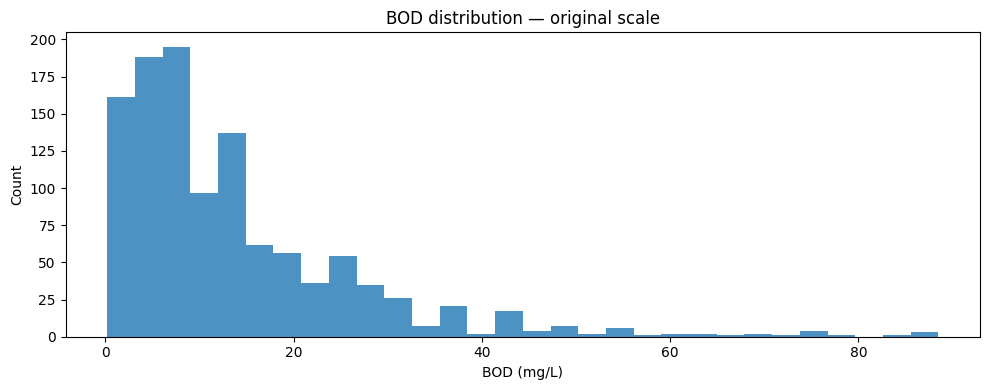

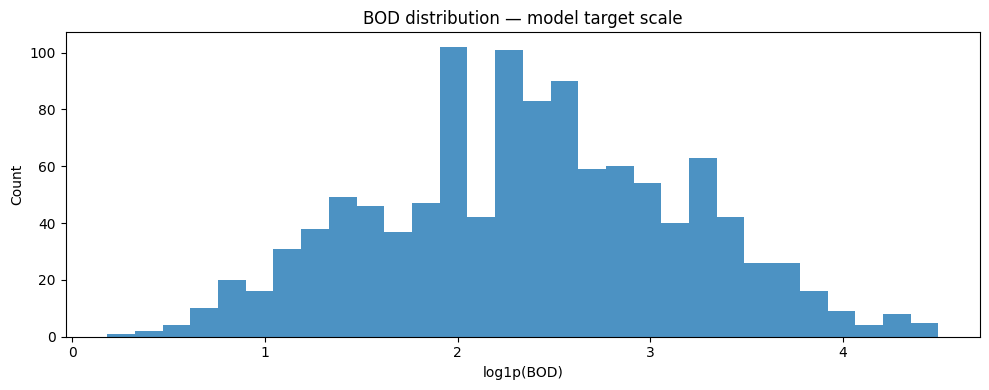

In [13]:
# Histograms: original and transformed BOD.
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(eda["BOD"].dropna(), bins=30, alpha=0.8)
ax.set_xlabel("BOD (mg/L)")
ax.set_ylabel("Count")
ax.set_title("BOD distribution — original scale")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase1_bod_distribution_original.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(eda["log_BOD"].dropna(), bins=30, alpha=0.8)
ax.set_xlabel("log1p(BOD)")
ax.set_ylabel("Count")
ax.set_title("BOD distribution — model target scale")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase1_bod_distribution_log1p.png", dpi=300, bbox_inches="tight")
plt.show()

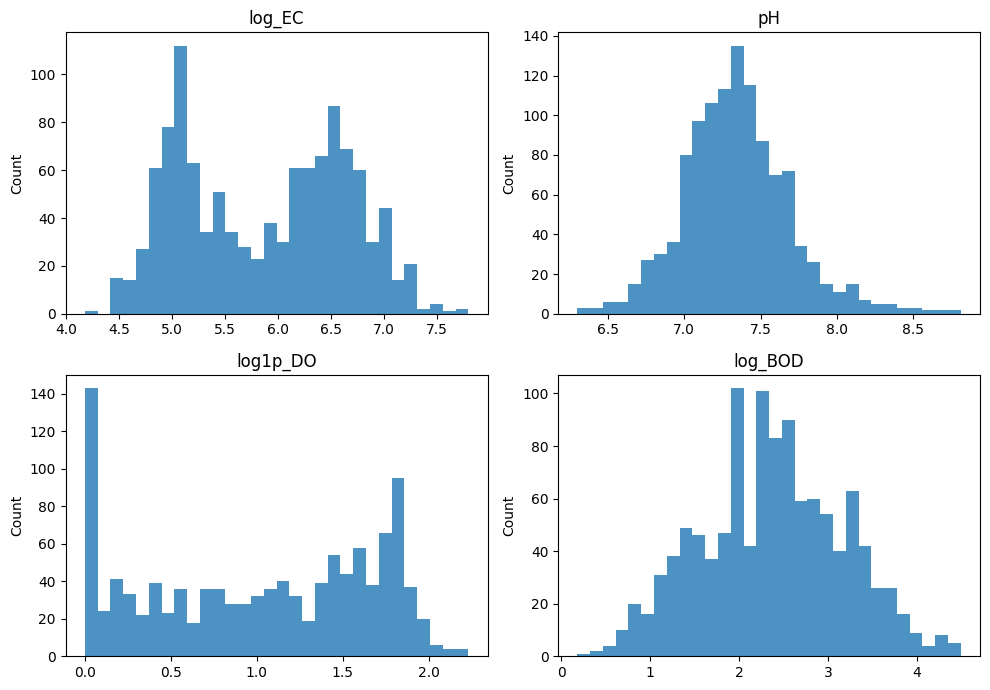

In [14]:
# Compact distribution panel for the principal predictors.
plot_cols = ["log_EC", "pH", "log1p_DO", "log_BOD"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), plot_cols):
    ax.hist(eda[col].dropna(), bins=30, alpha=0.8)
    ax.set_title(col)
    ax.set_ylabel("Count")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase1_core_variable_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 1.2 Bivariate relationships, correlations and collinearity

In [15]:
# Correlation matrix on transformed continuous variables.
corr_cols = ["log_BOD", "log_COD", "log_EC", "log_TDS", "pH", "log1p_DO", "Turbidity"]
corr_cols = [c for c in corr_cols if c in eda.columns]

corr = eda[corr_cols].corr(method="spearman")
display(corr.round(3))
corr.to_csv(RESULTS_DIR / "phase1_spearman_correlation_matrix.csv")

,log_BOD,log_COD,log_EC,log_TDS,pH,log1p_DO,Turbidity
log_BOD,1.0000,0.8720,0.7420,0.7530,0.1940,-0.7160,0.3160
log_COD,0.8720,1.0000,0.6950,0.7080,0.2150,-0.6640,0.3880
log_EC,0.7420,0.6950,1.0000,0.9760,0.2950,-0.7540,0.3550
log_TDS,0.7530,0.7080,0.9760,1.0000,0.2870,-0.7470,0.3740
pH,0.1940,0.2150,0.2950,0.2870,1.0000,-0.2110,0.2760
log1p_DO,-0.7160,-0.6640,-0.7540,-0.7470,-0.2110,1.0000,-0.2300
Turbidity,0.3160,0.3880,0.3550,0.3740,0.2760,-0.2300,1.0000


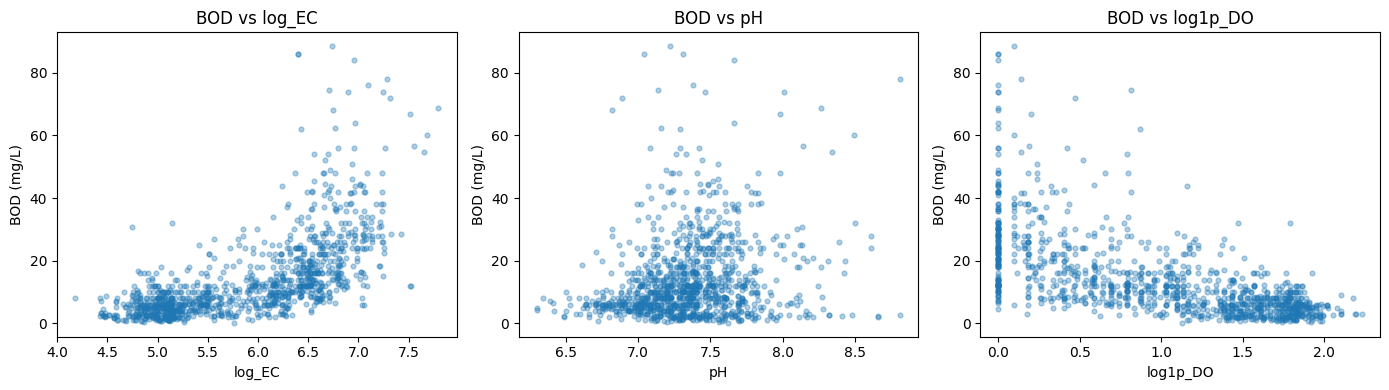

In [16]:
# Pairwise relationship plots with BOD on the original scale.
predictors = ["log_EC", "pH", "log1p_DO"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, x in zip(axes, predictors):
    ax.scatter(eda[x], eda["BOD"], s=12, alpha=0.35)
    ax.set_xlabel(x)
    ax.set_ylabel("BOD (mg/L)")
    ax.set_title(f"BOD vs {x}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase1_bod_bivariate_relationships.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
# Explicit EC/TDS collinearity check for the PCA decision.
ec_tds = locked["DS-4F"][["log_EC", "log_TDS", "pH", "log1p_DO"]].dropna()

print("Pearson correlation: log_EC vs log_TDS =", ec_tds["log_EC"].corr(ec_tds["log_TDS"]))
print("\nVIF:")
vif_table = vif(ec_tds, ["log_EC", "log_TDS", "pH", "log1p_DO"])
display(vif_table)
vif_table.to_csv(RESULTS_DIR / "phase1_vif_ec_tds.csv", index=False)

print("\nFold-safe PCA diagnostic (descriptive only; not used as a feature here):")
pca_diag = inspect_pca_block(
    locked["DS-4F"], ["log_EC", "log_TDS", "pH", "log1p_DO"], "PC1_EC_TDS"
)
display(pca_diag)
pca_diag.to_csv(RESULTS_DIR / "phase1_pca_ec_tds_diagnostic.csv")

Pearson correlation: log_EC vs log_TDS = 0.97839234530173

VIF:


,feature,VIF
0,log_EC,23.9000
1,log_TDS,23.7000
2,pH,1.1000
3,log1p_DO,2.4000



Fold-safe PCA diagnostic (descriptive only; not used as a feature here):


,log_EC,log_TDS
PC1 (EVR=0.989),0.7071,0.7071


In [18]:
# Partial correlations: unique linear association of each core predictor with
# log_BOD after controlling for the other two core predictors.
partial_rows = []
for x, controls in [
    ("log_EC", ["pH", "log1p_DO"]),
    ("pH", ["log_EC", "log1p_DO"]),
    ("log1p_DO", ["log_EC", "pH"]),
]:
    partial_rows.append(partial_corr(eda, x, "log_BOD", controls))

partial_table = pd.DataFrame(partial_rows)
display(partial_table)
partial_table.to_csv(RESULTS_DIR / "phase1_partial_correlations.csv", index=False)

,partial_r,partial_r2,x,y,controls,n
0,0.4207,0.1770,log_EC,log_BOD,"[pH, log1p_DO]",1131
1,-0.0580,0.0034,pH,log_BOD,"[log_EC, log1p_DO]",1131
2,-0.3392,0.1151,log1p_DO,log_BOD,"[log_EC, pH]",1131


## 1.3 Spatial heterogeneity — ICC and nested sum-of-squares shares

`nested_variance_decomposition` returns sum-of-squares (η²-type) shares for river, station-within-river and residual. They are not variance-component estimates; report them as shares.

In [19]:
# River-level and station-level heterogeneity.
# The ICC function uses the observational target directly; use log_BOD for the
# model-oriented decomposition because that is the declared target scale.
spatial_rows = []

for target in ["BOD", "log_BOD"]:
    for group in ["River", "Station_ID"]:
        rec = true_icc(eda.dropna(subset=[target, group]), target, group)
        rec["target"] = target
        rec["group"] = group
        spatial_rows.append(rec)

spatial_icc = pd.DataFrame(spatial_rows)[
    ["target","group","icc","sigma2_between","sigma2_within",
     "n_groups","n_total","mean_group_size","deff","n_eff"]
]

display(spatial_icc)
spatial_icc.to_csv(RESULTS_DIR / "phase1_icc.csv", index=False)

,target,group,icc,sigma2_between,sigma2_within,n_groups,n_total,mean_group_size,deff,n_eff
0,BOD,River,0.1202,21.0168,153.8084,5,1131,226.2000,28.0700,40
1,BOD,Station_ID,0.1193,20.2148,149.2793,30,1131,37.7000,5.3800,210
2,log_BOD,River,0.0617,0.0404,0.6143,5,1131,226.2000,14.8900,76
3,log_BOD,Station_ID,0.0702,0.0453,0.5995,30,1131,37.7000,3.5800,316


In [20]:
# Nested decomposition: River -> Station -> residual.
nested_bod = nested_variance_decomposition(
    eda.dropna(subset=["BOD", "River", "Station_ID"]),
    "BOD",
    level1_col="River",
    level2_col="Station_ID",
)
nested_log = nested_variance_decomposition(
    eda.dropna(subset=["log_BOD", "River", "Station_ID"]),
    "log_BOD",
    level1_col="River",
    level2_col="Station_ID",
)

nested_table = pd.DataFrame([nested_bod, nested_log], index=["BOD_mgL", "log1p_BOD"])
display(nested_table)
nested_table.to_csv(RESULTS_DIR / "phase1_nested_variance_decomposition.csv")

,SS_river,SS_station_within_river,SS_residual,SS_total,pct_river,pct_station,pct_residual,eta2_river
BOD_mgL,"17,417.0330","8,831.6970","164,356.5340","190,605.2640",9.1000,4.6000,86.2000,0.0914
log1p_BOD,34.7440,31.7130,660.0190,726.4760,4.8000,4.4000,90.9000,0.0478


In [21]:
# Descriptive station and river target summaries.
river_summary = (
    eda.groupby("River")
       .agg(
           n=("BOD","count"),
           BOD_mean=("BOD","mean"),
           BOD_median=("BOD","median"),
           BOD_sd=("BOD","std"),
           BOD_p90=("BOD", lambda x: x.quantile(.90)),
           BOD_max=("BOD","max"),
       )
       .reindex(RIVER_ORDER)
)
display(river_summary.round(3))
river_summary.to_csv(RESULTS_DIR / "phase1_river_bod_summary.csv")

,n,BOD_mean,BOD_median,BOD_sd,BOD_p90,BOD_max
River,,,,,,
Buriganga,512,11.4060,9.0000,8.4580,24.0000,56.0000
Turag,246,14.6960,10.0000,14.0500,31.4000,86.0000
Shitalakhya,184,10.9210,8.0000,9.7520,22.0000,49.0000
Balu River,112,18.9850,12.9000,16.4600,38.2900,88.5000
Tongi Khal,77,25.0560,14.4000,23.1660,65.2000,84.0000


## 1.4 Temporal structure — structural-break screening

The classical Chow test below treats all rows as independent. They are not: rows share station effects and sampling-campaign (year-month) effects (see 1.5–1.6), so its F statistic and p-value overstate the evidence. It is reported only for comparability with studies that use it.

The clustered Wald test fits the same break model — a post-2020 shift in intercept and slopes — with standard errors clustered two ways, by station and by campaign. It is repeated on the stations observed on both sides of the break, because the station network can change between years (see the station inventory in 0.1a and the year ranges per station). Without that restriction, a "break" can simply reflect a change in which sites were sampled.

,Year,n,BOD_mean,BOD_median,BOD_sd,log_BOD_mean
0,2017,199,14.4190,8.8000,15.6370,2.2440
1,2018,185,12.5770,8.4000,14.2750,2.2060
2,2019,207,12.2860,9.6000,10.0210,2.3520
3,2020,219,16.7440,12.0000,13.6430,2.6480
4,2021,130,12.1610,7.0000,10.9680,2.2660
5,2022,191,13.2610,8.6000,11.4230,2.4430


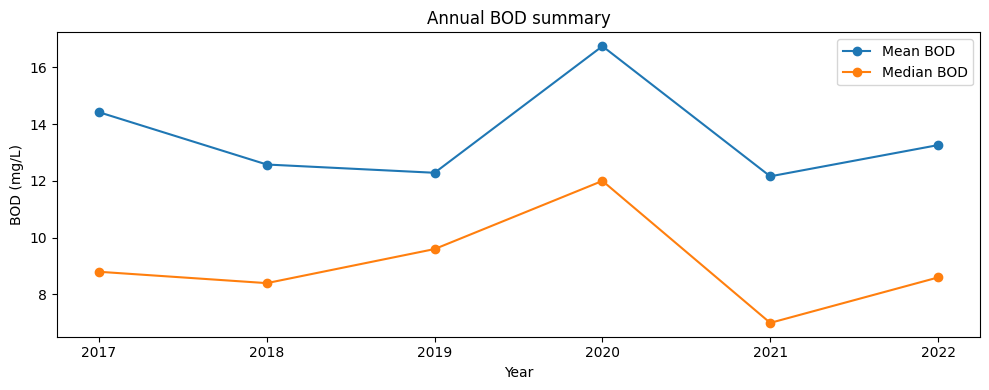

In [22]:
# Annual target summary.
annual = (
    eda.groupby("Year")
       .agg(
           n=("BOD","count"),
           BOD_mean=("BOD","mean"),
           BOD_median=("BOD","median"),
           BOD_sd=("BOD","std"),
           log_BOD_mean=("log_BOD","mean"),
       )
       .reset_index()
)
display(annual.round(3))
annual.to_csv(RESULTS_DIR / "phase1_annual_bod_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(annual["Year"], annual["BOD_mean"], marker="o", label="Mean BOD")
ax.plot(annual["Year"], annual["BOD_median"], marker="o", label="Median BOD")
ax.set_xlabel("Year")
ax.set_ylabel("BOD (mg/L)")
ax.set_title("Annual BOD summary")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase1_annual_bod_summary.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# Chow tests at the pre-specified 2020 break.
# The test is a screening diagnostic, not a license to use future observations
# in the predictive validation stage.
chow_features = ["log_EC", "pH", "log1p_DO"]

chow_input = eda[chow_features + ["log_BOD", "Year"]].dropna()
print(
    f"Chow input: n={len(chow_input)}, "
    f"before 2020={int((chow_input['Year'] < 2020).sum())}, "
    f"2020 onward={int((chow_input['Year'] >= 2020).sum())}"
)

chow_2020 = chow_test(
    chow_input,
    feature_cols=chow_features,
    target_col="log_BOD",
    break_col="Year",
    break_value=2020,
)
display(pd.Series(chow_2020, name="Chow_2020 (assumes independent rows)"))

pd.DataFrame([chow_2020]).to_csv(RESULTS_DIR / "phase1_chow_2020.csv", index=False)

# Clustered break test (src.stats.clustered_break_test).
eda["Campaign"] = (
    eda["Year"].astype(int).astype(str) + "-"
    + pd.to_numeric(eda["Month_num"]).astype(int).map("{:02d}".format)
)

span = eda.groupby("Station_ID")["Year"].agg(["min", "max"])
continuing = span.index[(span["min"] < 2020) & (span["max"] >= 2020)]
eda_cont = eda[eda["Station_ID"].isin(continuing)]

break_tests = pd.DataFrame([
    {"test": "Chow (independent rows)", "n": int(chow_2020["n_before"] + chow_2020["n_after"]),
     "F": chow_2020["F_stat"], "df_num": chow_2020["df_num"], "df_denom": chow_2020["df_den"],
     "p_value": chow_2020["p_value"]},
    clustered_break_test(eda, chow_features, "log_BOD", "Year", 2020,
                         ("Station_ID", "Campaign"), "Clustered Wald, all stations"),
    clustered_break_test(eda_cont, chow_features, "log_BOD", "Year", 2020,
                         ("Station_ID", "Campaign"), "Clustered Wald, stations observed before and after 2020"),
])
display(break_tests)
print(f"Stations observed on both sides of the 2020 break: {len(continuing)} of {eda['Station_ID'].nunique()}")
break_tests.to_csv(RESULTS_DIR / "phase1_break_tests_2020.csv", index=False)

Chow input: n=1131, before 2020=591, 2020 onward=540


F_stat        34.2120
p_value        0.0000
df_num         4.0000
df_den     1,123.0000
n_before     591.0000
n_after      540.0000
break_at   2,020.0000
Name: Chow_2020 (assumes independent rows), dtype: float64

,test,n,F,df_num,df_denom,p_value,clusters,post_intercept_shift,break_at,n_Station_ID,n_Campaign
0,Chow (independent rows),1131,34.2120,4.0000,"1,123.0000",0.0000,NaN,NaN,NaN,NaN,NaN
1,"Clustered Wald, all stations",1131,8.1648,4.0000,29.0000,0.0002,Station_ID + Campaign,1.1829,"2,020.0000",30.0000,69.0000
2,"Clustered Wald, stations observed before and a...",941,11.0365,4.0000,19.0000,0.0001,Station_ID + Campaign,0.4011,"2,020.0000",20.0000,69.0000


Stations observed on both sides of the 2020 break: 20 of 30


## 1.5 Effective sample size

The design effect is computed for four clusterings: river, station, year, and sampling campaign (year-month). The campaign row matters most for temporal claims. All stations sampled in the same month share that month's hydrological conditions; 1.6 quantifies how much of the variance month explains compared with river and station.

Station and campaign clustering are **crossed**, not nested, so their design effects do not simply multiply. Treat each `effective_N` as an upper bound on independent information under that clustering alone. The binding limit for any claim is the smallest of them, and for Forward-Chain it is ultimately the number of test years (4).

In [24]:
# Design-effect-adjusted effective sample size.
# Descriptive: how much repeated/grouped observation reduces independent information.
if "Campaign" not in eda:
    eda["Campaign"] = (
        eda["Year"].astype(int).astype(str) + "-"
        + pd.to_numeric(eda["Month_num"]).astype(int).map("{:02d}".format)
    )

eff_rows = []
for group in ["River", "Station_ID", "Year", "Campaign"]:
    rec = true_icc(eda, "log_BOD", group)
    eff_rows.append({
        "grouping": group,
        "N": rec["n_total"],
        "groups": rec["n_groups"],
        "mean_group_size": rec["mean_group_size"],
        "ICC": rec["icc"],
        "design_effect": rec["deff"],
        "effective_N": rec["n_eff"],
        "effective_fraction": rec["n_eff"] / rec["n_total"],
    })

effective_n = pd.DataFrame(eff_rows)
display(effective_n.round(4))
effective_n.to_csv(RESULTS_DIR / "phase1_effective_sample_size.csv", index=False)

binding = effective_n.loc[effective_n["effective_N"].idxmin()]
print(
    f"Smallest effective N: {int(binding['effective_N'])} under {binding['grouping']} clustering "
    f"(ICC = {binding['ICC']:.3f})."
)

,grouping,N,groups,mean_group_size,ICC,design_effect,effective_N,effective_fraction
0,River,1131,5,226.2000,0.0617,14.8900,76,0.0672
1,Station_ID,1131,30,37.7000,0.0702,3.5800,316,0.2794
2,Year,1131,6,188.5000,0.0402,8.5400,132,0.1167
3,Campaign,1131,69,16.4000,0.6442,10.9100,104,0.0920


Smallest effective N: 76 under River clustering (ICC = 0.062).


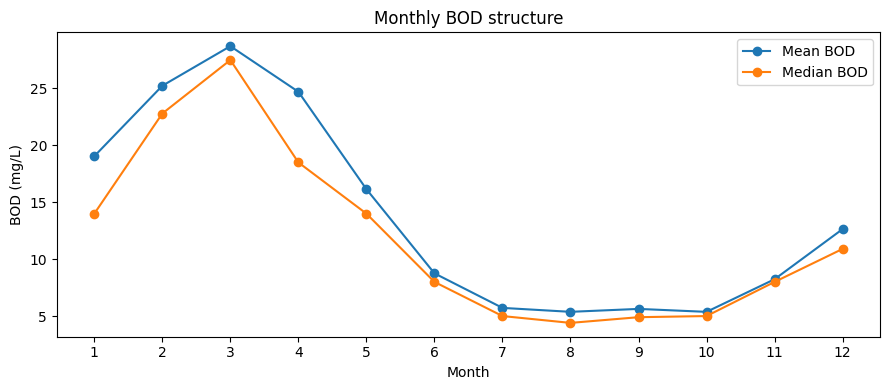

In [25]:
# Monthly/seasonal descriptive structure.
monthly = (
    eda.groupby("Month_num")
       .agg(
           n=("BOD","count"),
           BOD_mean=("BOD","mean"),
           BOD_median=("BOD","median"),
           log_BOD_mean=("log_BOD","mean"),
       )
       .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly["Month_num"], monthly["BOD_mean"], marker="o", label="Mean BOD")
ax.plot(monthly["Month_num"], monthly["BOD_median"], marker="o", label="Median BOD")
ax.set_xticks(range(1,13))
ax.set_xlabel("Month")
ax.set_ylabel("BOD (mg/L)")
ax.set_title("Monthly BOD structure")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase1_monthly_bod_summary.png", dpi=300, bbox_inches="tight")
plt.show()

monthly.to_csv(RESULTS_DIR / "phase1_monthly_bod_summary.csv", index=False)

## 1.6 Temporal variance decomposition — month and season

The monthly profile is descriptive, but the magnitude of temporal structure must be quantified before deciding whether calendar information is useful in prediction. We therefore calculate eta-squared for **month** and **season** on `log_BOD`, using the same complete-case EDA population. These are in-sample variance decompositions and are **not** substitutes for OOS R².

We also retain the month profile by river to assess whether the seasonal pattern is broadly shared or strongly river-specific. Transferability of a month effect to an unseen river must be demonstrated by LOSO-River rather than assumed from the pooled decomposition.

In [26]:
# Ensure Month_num is numeric before grouping
eda = eda.copy()
eda['Month_num'] = pd.to_numeric(eda['Month_num'], errors='coerce')

# Quantify month and season effects on log_BOD.

def eta_squared_oneway(df, target, group):

    x = df[[target, group]].dropna().copy()

    grand = x[target].mean()

    ss_total = ((x[target] - grand) ** 2).sum()

    group_stats = x.groupby(group)[target].agg(['count', 'mean'])

    ss_between = (
        group_stats['count']
        * (group_stats['mean'] - grand) ** 2
    ).sum()

    eta2 = ss_between / ss_total if ss_total > 0 else np.nan

    return {
        'group': group,
        'n': len(x),
        'levels': x[group].nunique(),
        'SS_between': ss_between,
        'SS_total': ss_total,
        'eta_squared': eta2
    }


temporal_variance = pd.DataFrame([
    eta_squared_oneway(eda, 'log_BOD', 'Month_num'),
    eta_squared_oneway(eda, 'log_BOD', 'Season'),
])

display(temporal_variance.round(4))

temporal_variance.to_csv(
    RESULTS_DIR / 'phase1_temporal_variance_decomposition.csv',
    index=False
)


# Month-by-river profile

month_river = (
    eda.groupby(['River', 'Month_num'])
       .agg(
           n=('log_BOD', 'count'),
           log_BOD_mean=('log_BOD', 'mean'),
           BOD_mean=('BOD', 'mean')
       )
       .reset_index()
)

display(month_river.head(20))

month_river.to_csv(
    RESULTS_DIR / 'phase1_month_river_bod_summary.csv',
    index=False
)


# Sampling balance by month

monthly_balance = (
    eda.groupby('Month_num')
       .size()
       .rename('n')
       .reset_index()
)

display(monthly_balance)

monthly_balance.to_csv(
    RESULTS_DIR / 'phase1_monthly_sampling_balance.csv',
    index=False
)


# Sampling balance by season

season_balance = (
    eda.groupby('Season')
       .size()
       .rename('n')
       .reset_index()
)

display(season_balance)

season_balance.to_csv(
    RESULTS_DIR / 'phase1_season_sampling_balance.csv',
    index=False
)

,group,n,levels,SS_between,SS_total,eta_squared
0,Month_num,1131,12,389.6218,726.4760,0.5363
1,Season,1131,2,212.2739,726.4760,0.2922


,River,Month_num,n,log_BOD_mean,BOD_mean
0,Balu River,1,9,3.4471,32.6222
1,Balu River,2,11,3.3865,31.6182
2,Balu River,3,10,3.5647,35.0000
3,Balu River,4,8,3.5057,37.1625
4,Balu River,5,9,2.5072,11.8111
5,Balu River,6,6,2.5923,12.6000
6,Balu River,7,10,2.3458,12.4600
7,Balu River,8,11,1.8889,6.9727
8,Balu River,9,8,2.4173,12.2250
9,Balu River,10,9,2.0938,9.0111


,Month_num,n
0,1,100
1,2,106
2,3,96
3,4,74
4,5,89
5,6,76
6,7,97
7,8,96
8,9,94
9,10,102


,Season,n
0,Dry,577
1,Wet,554


# Phase 0–1 reproducibility manifest

This final cell records the key locked choices and generated artifacts. It is intended to make the transition into the modeling phase auditable.

In [27]:
manifest = {
    "analysis_phase": "Phase 0 + Phase 1",
    "seed": SEED,
    "raw_file": rel(RAW_CSV),
    "target_transform": TARGET_TRANSFORM,
    "primary_target": PRIMARY_TARGET,
    "primary_threshold_mgL": PRIMARY_THRESHOLD,
    "expected_dataset_sizes": EXPECTED_N,
    "feature_configs": FEATURE_CONFIGS,
    "primary_outer_protocol": "LOSO-River",
    "secondary_outer_protocols": ["LOSO-Station", "Forward-Chain"],
    "comparison_protocols": ["Stratified 5-fold", "Random 80/20"],
    "cross_river_duplicates": (
        int(cross_dupes["Observation_Key"].nunique()) if not cross_dupes.empty else 0
    ),
    "integrity_status": dict(zip(integrity_table["check"], integrity_table["status"])),
    "ratio_flag_rows": int(n_ratio_flag),
    "bod_equals_cod_rows": int(n_bod_eq_cod),
    "ds3f_rows_missing_from_ds4f_by_river_year": {
        f"{r.River} {int(r.Year)}": int(r.rows_in_DS3F_not_in_DS4F) for r in tds_gap.itertuples()
    },
    "fold_keys_file": rel(FOLD_KEYS_PATH),
    "fold_indices_note": "fold_indices.json holds DS-3F row positions only; use fold_keys_by_dataset.json to verify folds for any dataset",
    "effective_n": dict(zip(effective_n["grouping"], effective_n["effective_N"].astype(int))),
    "break_tests_2020": break_tests[["test", "F", "p_value"]].to_dict("records"),
    "generated_results_dir": rel(RESULTS_DIR),
    "generated_figures_dir": rel(FIGURES_DIR),
    "fold_file": rel(FOLDS_PATH),
}

manifest_path = RESULTS_DIR / "phase0_1_manifest.json"
from src.provenance import provenance   # code + data hashes, environment
manifest["provenance"] = provenance()
manifest_path.write_text(json.dumps(manifest, indent=2, default=str))

display(pd.Series(manifest, name="value"))
print(f"\nManifest saved to: {rel(manifest_path)}")
print("\nPhase 0 + Phase 1 complete.")

analysis_phase                                                               Phase 0 + Phase 1
seed                                                                                        42
raw_file                                     data/DOE_Data...
target_transform                                                                         log1p
primary_target                                                                         log_BOD
primary_threshold_mgL                                                                        6
expected_dataset_sizes                       {'DS-3F': 1131, 'DS-4F': 1083, 'DS-4F-ALK': 11...
feature_configs                              {'FS-A': {'cols': ['EC', 'pH', 'DO'], 'dataset...
primary_outer_protocol                                                              LOSO-River
secondary_outer_protocols                                        [LOSO-Station, Forward-Chain]
comparison_protocols                                         [Stratified 5-fold, Ra


Manifest saved to: results/phase0_1_manifest.json

Phase 0 + Phase 1 complete.
